# NumPyの配列 ― メモリ構造と要素へのアクセス

## この章で学ぶこと

数値計算では、たくさんの数値をまとめて扱います。Python のリストは手軽ですが、数値の計算には向いていません。この章では、NumPy の配列(ndarray)がなぜ速いのかを、メモリの使われ方から確認します。

* リスト、`array` 配列、ndarray のメモリ構造の違い
* `shape` と `strides` が表すもの
* メモリを共有するビューの作り方
* 整数配列とブール配列を使った要素の取り出し方
* 多次元配列の添字の読み方

標準の Python では、一連の値はリストに保存します。しかし、リストの要素は任意のオブジェクトであり、リストが持つのはオブジェクトへのポインタです。`[1, 2, 3]` のような単純なリストでも、3 つのポインタと 3 つの整数オブジェクトが必要になります。数値計算でこの構造を使うと、メモリと CPU 時間を無駄にします。

標準ライブラリの `array` モジュールは、数値を連続したメモリに直接保存します。C 言語の 1 次元配列に似ていますが、多次元配列を扱えず、演算のための関数もありません。

NumPy はこの 2 つの欠点を補うために作られました。NumPy が提供する基本のオブジェクトは次の 2 つです。

* `ndarray` (n-dimensional array object)：単一のデータ型の要素を持つ多次元配列。以下では単に配列と呼びます。
* `ufunc` (universal function object)：配列の要素ごとに計算する関数。

この本のコードは NumPy 2.5 系で実行しています。次のコードでバージョンを確認します。

In [1]:
import helper.magics          # %C マジック(式と値を並べて表示する)
from matplotlib import pyplot as plt
import helper.matplotlib      # matplotlib の日本語フォント設定
import numpy as np

np.__version__

'2.5.4'

## リストと配列のメモリ構造

まず、NumPy の配列とリスト、`array` モジュールの配列を比べます。値がメモリのどこに置かれるかを知ると、NumPy の配列が速い理由が見えてきます。

Python の標準のデータ型に配列はありません。多次元の配列を表すには、リストを入れ子にします。しかし Python ではすべてがオブジェクトです。3×3 の 2 次元配列を表すには、次の図のように 4 つのリストオブジェクトと 9 つの浮動小数点数オブジェクトが必要になります。図の各リストは固定サイズのメモリ領域で、`ob_item` フィールドが要素へのポインタの配列を指しています。浮動小数点数もオブジェクトです。値そのものに加えて、オブジェクトに必要な情報(図の float header の部分)も保持します。

![ネストされたリストのメモリ構造](images/nested-list.svg "")

入れ子のリストはメモリを余分に使い、データがメモリのあちこちに散らばります。CPU のキャッシュに載りにくいので、アクセスも遅くなります。次の `iter_object_sizes()` は `sys.getsizeof()` を使って、入れ子のリストが使うメモリを合計します。

In [2]:
import sys

nested_list = [[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]]


def iter_object_sizes(obj):
    """オブジェクト自身と、その中身のサイズを順に返す。"""
    yield sys.getsizeof(obj)

    if isinstance(obj, list):
        for item in obj:
            yield from iter_object_sizes(item)


sum(iter_object_sizes(nested_list))

560

この環境では、9 つの値を持つ入れ子のリスト全体で 560 バイトになりました。値そのものは 9 × 8 = 72 バイトなので、残りのほとんどはオブジェクトの管理情報です。

`array` モジュールの `array` 配列は、複数の数値を連続したバイナリデータとして保存します。メモリ構造は次の図のとおりです。`ob_item` フィールドがデータの領域を指し、`ob_descr` フィールドが要素の型を表すオブジェクトを指します。ただし 1 次元のみで、多次元配列は表せません。

![array 配列のメモリ構造](images/array.svg "")

In [3]:
from array import array

# 倍精度浮動小数点数("d")を 9 個。値は連続したメモリに並ぶ
array_1d = array("d", [1, 2, 3, 4, 5, 6, 7, 8, 9])
print(f"array オブジェクトのサイズ: {sys.getsizeof(array_1d)} バイト")

array オブジェクトのサイズ: 152 バイト


## ndarrayのメモリ構造

NumPy の `ndarray` も、`array` 配列と同じく、要素の値をデータ領域に直接並べます。値のほかに、配列の解釈に必要な情報を属性として持ちます。

* `dtype`：要素のデータ型
* `ndim`：次元数
* `shape`：各軸の長さ
* `strides`：各軸で添字を 1 増やしたときに進むバイト数
* `flags`：メモリの持ち方に関するフラグ

次の図は `ndarray` のメモリ構造です。

![NumPy 配列のメモリ構造](images/ndarray.svg "")

入れ子のリストを `ndarray` に変換し、使うメモリを比べます。

In [4]:
from helper.numpy import array_pretty

ndarray_2d = np.asarray(nested_list)
array_pretty(ndarray_2d)
print(f"オブジェクト: {sys.getsizeof(ndarray_2d)} バイト, データ: {ndarray_2d.nbytes} バイト")

float64 shape:(3, 3) strides:(24, 8) W|C|O
[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
オブジェクト: 200 バイト, データ: 72 バイト


`array_pretty()` は、配列の型・形状・`strides`・フラグを 1 行で表示し、その下に値を表示します。この環境では、オブジェクトが 200 バイト、データが 72 バイトで、合わせて 272 バイトでした。入れ子のリストの 560 バイトと比べると半分以下です。値は 1 つの連続した領域にまとまっているので、要素数が増えるほど差は開きます。

## データ領域をバイト列として見る

`tobytes()` メソッドを使うと、データ領域の生のバイト列を取り出せます。戻り値は `bytes` オブジェクトです。❶ は先頭 8 バイトを 16 進数で表示しており、これは倍精度浮動小数点数 1.0 のバイナリデータです。❷ は標準ライブラリの `struct` モジュールでこのバイト列を解釈します。`"9d"` は「倍精度浮動小数点数が 9 個」という意味です。

In [5]:
import struct

raw_bytes = ndarray_2d.tobytes()          # データ領域をそのままバイト列にする
print(raw_bytes[:8].hex(" "))             # ❶ 先頭 8 バイト = 1.0
struct.unpack("9d", raw_bytes)            # ❷ 9 個の倍精度浮動小数点数として読む

00 00 00 00 00 00 f0 3f


(1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0)

## メモリを共有する配列

`ndarray` は、ほかのオブジェクトのデータ領域を共有できます。❶ は `numpy.asarray()` で `array` 配列 `array_1d` を `ndarray` に変換しています。`asarray()` は要素の型を自動で決めます。❷ は `numpy.frombuffer()` で、バイト列 `raw_bytes` とデータを共有する配列を作ります。引数 `dtype` で要素の型を指定し、`"f8"` は 8 バイトの倍精度浮動小数点数を意味します。

次のコードで、3 つの配列の `owndata` と `writeable` フラグを調べます。`owndata` が `True` ならその配列がデータ領域を所有しており、`False` ならデータはほかのオブジェクトから渡されています。`writeable` が `True` ならデータに書き込めます。

`ndarray_2d` は入れ子のリストから作ったので、`asarray()` がすべてのデータをコピーし、自分でデータ領域を持ちます。`view_from_array` は `array_1d` とデータを共有するので `owndata` は `False` です。`view_from_bytes` は `raw_bytes` と共有しており、`bytes` は変更できないので `writeable` が `False` になります。

In [6]:
view_from_array = np.asarray(array_1d)                    # ❶ array 配列から ndarray を作る
view_from_bytes = np.frombuffer(raw_bytes, dtype="f8")    # ❷ バイト列とメモリを共有する

print(f"ndarray_2d      owndata={ndarray_2d.flags.owndata}, writeable={ndarray_2d.flags.writeable}")
print(f"view_from_array owndata={view_from_array.flags.owndata}, writeable={view_from_array.flags.writeable}")
print(f"view_from_bytes owndata={view_from_bytes.flags.owndata}, writeable={view_from_bytes.flags.writeable}")

ndarray_2d      owndata=True, writeable=True
view_from_array owndata=False, writeable=True
view_from_bytes owndata=False, writeable=False


データを共有するときは、共有元のオブジェクトを残しておく必要があります。そのため `ndarray` は `base` 属性に共有元のオブジェクトを保持します。次の図は、`view_from_array` と `view_from_bytes` が参照しているオブジェクトとの関係を示しています。

![他のオブジェクトとメモリを共有する配列](images/ndarray-view.svg "")

次のコードで `base` 属性を確認できます。

In [7]:
view_from_array.base.obj is array_1d, view_from_bytes.base is raw_bytes

(True, True)

## shapeとstrides属性

`shape` 属性は配列の形状を、各軸の長さのタプルで持ちます。`ndarray_2d` の `shape` は `(3, 3)` なので 2 次元配列で、第 0 軸の長さが 3、第 1 軸の長さも 3 です。

`strides` 属性は、各軸の添字を 1 増やしたときに、データ領域のアドレスが何バイト進むかを持ちます。`ndarray_2d` の `strides` は `(24, 8)` です。第 0 軸の添字を 1 増やすとアドレスは 24 バイト進み、これは倍精度浮動小数点数 3 個分です。第 1 軸の添字を 1 増やすと 8 バイト進み、これは 1 個分です。

データがメモリに連続して並んでいるとき、`strides` の値は、その軸を 1 つ進むのに飛ばす要素数に要素のバイト数を掛けた値になります。`ndarray_2d` では、第 0 軸が 3 × 8 = 24 バイト、第 1 軸が 1 × 8 = 8 バイトです。多次元配列の並べ方には C 言語の形式と Fortran 言語の形式があります。C 言語では第 0 軸が最も上位で、第 0 軸の添字を 1 増やすとアドレスが最も大きく進みます。Fortran 言語では第 0 軸が最も下位です。

配列の `T` 属性を使うと、`strides` を入れ替えた配列が得られます。データ領域は元の配列と共有します。次のコードでは、`ndarray_2d` がデータを所有し、`ndarray_2d_t` はそのビューになります。

In [8]:
ndarray_2d_t = ndarray_2d.T
array_pretty(ndarray_2d)
array_pretty(ndarray_2d_t)

float64 shape:(3, 3) strides:(24, 8) W|C|O
[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
float64 shape:(3, 3) strides:(8, 24) W|F
[[1. 4. 7.]
 [2. 5. 8.]
 [3. 6. 9.]]


![配列の転置と元の配列の関係](images/ndarray-transpose.svg "")

`ndarray_2d` の `C_CONTIGUOUS` フラグが `True` なら、要素は C 言語の形式で連続しています。`ndarray_2d_t` では `F_CONTIGUOUS` が `True` になり、Fortran 言語の形式で連続しています。

In [9]:
print(ndarray_2d.flags["C_CONTIGUOUS"], ndarray_2d_t.flags["F_CONTIGUOUS"])

True True


スライスを使うと、同じデータから `shape` と `strides` の違う配列を作れます。さらに、この 2 つの属性を直接指定すると、スライスでは作れない配列も作れます。次の例では、補助モジュールの `as_strided()` を使います。

In [10]:
from numpy.lib.stride_tricks import as_strided

a = np.arange(6, dtype=np.int32)                  # 要素は 4 バイト
b = as_strided(a, shape=(4, 3), strides=(4, 4))   # strides はバイト数で指定する
%C a; b

        a                b     
------------------  -----------
[0, 1, 2, 3, 4, 5]  [[0, 1, 2],
                     [1, 2, 3],
                     [2, 3, 4],
                     [3, 4, 5]]


`as_strided()` の `strides` はバイト数で指定します。`a` の要素は 4 バイトなので、`(4, 4)` を指定すると、行も列も 1 要素ずつずれた配列になります。`b` は `a` とデータを共有し、隣り合う行は 2 つの要素を重ねています。NumPy 2 では `np.arange()` の既定の型が int64(8 バイト)になったため、ここでは `dtype=np.int32` を明示しています。

次のように `a[2]` を書き換えると、`b` の 0〜2 行目の対応する要素も変わります。

In [11]:
a[2] = 20
b

array([[ 0,  1, 20],
       [ 1, 20,  3],
       [20,  3,  4],
       [ 3,  4,  5]], dtype=int32)

データをブロックに分けて処理するとき、となりのブロックと少し重ねたい場合があります。そんなときは、この方法でデータを重ねた配列を作れます。ただし `as_strided()` はメモリの境界を検査しないので、`shape` と `strides` の指定を誤ると、思わぬ値になったり、エラーが起きたりします。

## メモリビュー

`view()` メソッドを使うと、同じデータ領域を別の `dtype` で見る配列を作れます。同じバイナリデータを、違う数値型として解釈できます。

In [12]:
a = np.array([[0, 1], [2, 3], [4, 5]], dtype=np.float32)
b = a.view(np.uint32)     # 4 バイトを符号なし 32 ビット整数として見る
c = a.view(np.uint8)      # 1 バイトずつ見る
%C 2 b; c

            b                                   c                     
--------------------------  ------------------------------------------
[[         0, 1065353216],  [[  0,   0,   0,   0,   0,   0, 128,  63],
 [1073741824, 1077936128],   [  0,   0,   0,  64,   0,   0,  64,  64],
 [1082130432, 1084227584]]   [  0,   0, 128,  64,   0,   0, 160,  64]]


`a` の要素は単精度浮動小数点数で 4 バイトです。`a.view(np.uint32)` は同じメモリを符号なし 32 ビット整数として扱います。`a.view(np.uint8)` は 1 バイトずつ扱うので、形状が `(3, 8)` の配列になります。どちらも `a` とメモリを共有しており、`a[0, 0]` を書き換えると `b[0, 0]` と `c[0, :4]` も変わります。

In [13]:
a[0, 0] = 3.14
%C 2 b[0, 0]; c[0, :4]

       b[0, 0]               c[0, :4]      
---------------------  --------------------
np.uint32(1078523331)  [195, 245,  72,  64]


## ビット列を整数として使う例

`view()` の面白い使い方を見てみましょう。ゲーム『Quake III Arena』の C 言語のソースコードには、平方根の逆数を計算する `Q_rsqrt()` という関数があります。中身はニュートン法による近似計算です。その中に、魔法の数字 `0x5f3759df` を使って、単精度浮動小数点数を 32 ビット整数として扱う部分があります。

:::{seealso}
https://en.wikipedia.org/wiki/Fast_inverse_square_root

ウィキペディアの、『Quake』で `0x5f3759df` を使って平方根の逆数を求めるアルゴリズムの説明
:::

```c
float Q_rsqrt( float number )
{
	long i;
	float x2, y;
	const float threehalfs = 1.5F;
 
	x2 = number * 0.5F;
	y  = number;
	i  = * ( long * ) &y;                       // 浮動小数点数のビットレベルハック
	i  = 0x5f3759df - ( i >> 1 );               // これは一体何？
	y  = * ( float * ) &i;
	y  = y * ( threehalfs - ( x2 * y * y ) );   // 最初のニュートン反復
	return y;
}
```

同じ計算を NumPy で書くと次のようになります。

In [14]:
x = np.linspace(0.1, 10, 100)
y = x.astype(np.float32)              # ❶ 単精度浮動小数点数に変換する
half_x = y * 0.5
bits = y.view(np.int32)               # ❷ 同じメモリを 32 ビット整数として見る
bits[:] = 0x5F3759DF - (bits >> 1)    # ❸ 整数として計算し、書き戻す
y = y * (1.5 - half_x * y * y)        # ❹ ニュートン法を 1 回行う
np.max(np.abs(1 / np.sqrt(x) - y))    # ❺ 真の値との最大誤差

np.float64(0.005045614041059743)

❶ `linspace()` が作る配列は倍精度浮動小数点数なので、`astype()` で単精度浮動小数点数に変換します。❷ `view()` で、`y` とメモリを共有する 32 ビット整数配列 `bits` を作ります。❸ 整数配列にこの演算を行い、結果を同じ配列に書き戻します。`bits` と `y` はメモリを共有しているので、この時点で `y` の値も変わります。ここは `bits = 0x5F3759DF - (bits >> 1)` と書いてはいけません。そう書くと `bits` は新しい配列になり、`y` は変わりません。

❹ ニュートン法の反復を 1 回行います。ここは `y = ...` と書いているので、`y` は新しい配列になり、`bits` との共有はなくなります。この行には配列の演算がいくつも出てきますが、詳しくは次の章で説明します。❺ 最後に、真の値と近似値の最大誤差を表示します。次のグラフは、横軸に `x`、縦軸に誤差をとったものです。`x` が小さくなると絶対誤差は大きくなります。ただし、そのときの関数の値も大きいので、相対的な誤差は大きくありません。

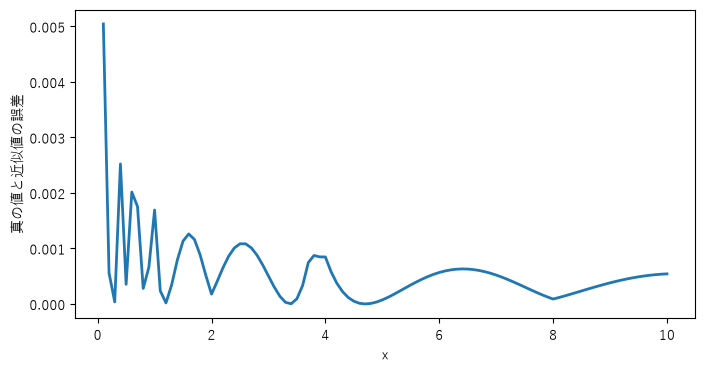

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(x, 1 / np.sqrt(x) - y, lw=2)
plt.xlabel("x")
plt.ylabel("真の値と近似値の誤差")
plt.show()

## 1次元配列の要素へのアクセス

配列の要素を取り出すには、整数、スライス、整数のリスト、整数配列、ブール配列を添字に使えます。整数とスライスの使い方はリストと同じです。

* `a[5]`：整数の添字で、1 つの要素を取り出す
* `a[3:5]`：スライスで、`a[3]` から `a[5]` の手前までを取り出す
* `a[:5]`：開始を省略すると `a[0]` からになる
* `a[:-1]`：負の添字は配列の最後から数える

In [16]:
a = np.asarray([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
%C a[5]; a[3:5]; a[:5]; a[:-1]

    a[5]     a[3:5]       a[:5]                  a[:-1]          
-----------  ------  ---------------  ---------------------------
np.int64(5)  [3, 4]  [0, 1, 2, 3, 4]  [0, 1, 2, 3, 4, 5, 6, 7, 8]


* `a[1:-1:2]`：3 番目の引数はステップで、2 なら 1 つおきになる
* `a[::-1]`：開始と終了を省略してステップを -1 にすると、全体が逆順になる
* `a[5:1:-2]`：ステップが負のときは、開始を終了より大きくする

In [17]:
%C a[1:-1:2]; a[::-1]; a[5:1:-2]

 a[1:-1:2]               a[::-1]              a[5:1:-2]
------------  ------------------------------  ---------
[1, 3, 5, 7]  [9, 8, 7, 6, 5, 4, 3, 2, 1, 0]  [5, 3]   


リストと違い、スライスで取り出した配列は元の配列のビューです。データ領域を共有し、`shape`、`strides`、`data` 属性だけが変わります。次の図は、配列 `a` と `b` のメモリの関係です。

![配列スライスビュー](images/ndarray-slice.svg "")

In [18]:
b = a[1::2]
print(f"{b.strides=} {b.shape=} {b.base is a}")

b.strides=(16,) b.shape=(5,) True


添字が整数のリストや配列のときは、その各要素が添字になります。ブールのリストや配列のときは、`True` の位置の要素を取り出します。これらの添字を使うと、結果は元の配列のコピーになり、データを共有しません。

In [19]:
c = a[[1, 3, 4, 5]]
d = a[[True, False, False, True, True, False, False, True, True, True]]
print(f"{c=} {c.base=}")
print(f"{d=} {d.base=}")

c=array([1, 3, 4, 5]) c.base=None
d=array([0, 3, 4, 7, 8, 9]) d.base=None


ブール配列は、ブール演算の ufunc で作るのが普通です。ufunc は次の章で説明します。ここでは簡単な例で、ブール配列の添字を確認します。

In [20]:
rng = np.random.default_rng(0)      # 毎回同じ結果になるように種を固定する
x = rng.integers(0, 10, 6)          # 0〜9 の整数を 6 個
%C x; x > 5

        x                             x > 5                   
------------------  ------------------------------------------
[8, 6, 5, 2, 3, 0]  [ True,  True, False, False, False, False]


式 `x > 5` は、`x` の各要素を 5 と比べてブール配列を返します。`True` の位置の値が 5 より大きいという意味です。このブール配列を添字にすると、5 より大きい要素だけを取り出せます。

In [21]:
x[x > 5]

array([8, 6])

## 多次元配列の要素へのアクセス

多次元配列では、軸が複数あるので、添字も複数の値で表します。NumPy はタプルを添字に使い、タプルの各要素が各軸に対応します。次の図は形状が `(6, 6)` の配列で、各添字が選ぶ範囲を示しています。添字は 2 つの要素を持つタプルで、第 0 要素が第 0 軸(縦)、第 1 要素が第 1 軸(横)に対応します。

![多次元配列のスライスインデックス](images/ndarray-multindex.svg "")

:::{admonition} なぜタプルを添字に使うのか
:class: note
Python の添字の構文(`[]` でシーケンスの要素にアクセスする)は多次元に対応していません。しかし添字には任意のオブジェクトを使えるので、NumPy はタプルを添字にして多次元の要素にアクセスします。タプルなら複数の軸の添字をまとめて表せます。Python ではタプルの要素を丸括弧で囲むことが多いですが、カンマで区切れば足ります。例えば `x, y = y, x` はタプルで値を交換する例です。したがって `a[1, 2]` と `a[(1, 2)]` は同じで、どちらもタプル `(1, 2)` を添字にしています。
:::

In [22]:
a = np.arange(0, 60, 10)[:, None] + np.arange(0, 6)
%C a[0, 3:5]; a[4:, 4:]; a[:, 2]; a[2::2, ::2]

a[0, 3:5]  a[4:, 4:]           a[:, 2]            a[2::2, ::2] 
---------  ----------  ------------------------  --------------
[3, 4]     [[44, 45],  [ 2, 12, 22, 32, 42, 52]  [[20, 22, 24],
            [54, 55]]                             [40, 42, 44]]


添字のタプルが整数とスライスだけなら、結果は元の配列のビューになります。

In [23]:
b = a[0, 3:5]
b.base is a

True

添字はタプルなので、タプルを変数に保存して、同じタプルで複数の配列にアクセスできます。次の例では `a[idx]` と `a[::2, 2:]` は同じです。

In [24]:
idx = slice(None, None, 2), slice(2, None)
a[idx]

array([[ 2,  3,  4,  5],
       [22, 23, 24, 25],
       [42, 43, 44, 45]])

組み込み関数 `slice()` で添字を作るのは面倒なので、NumPy は `s_` オブジェクトを用意しています。`s_` に多次元の添字を渡すと、その添字を表すタプルが得られます。

In [25]:
np.s_[::2, 2:]

(slice(None, None, 2), slice(2, None, None))

多次元配列の添字には、整数のリストや配列、ブール配列も使えます。次の図のように、これらを添字にすると結果はコピーになり、元の配列は変わりません。

![整数配列とブール配列を使用して多次元配列の要素にアクセスする](images/ndarray-multindex2.svg "")

次の式の添字は 2 つの要素を持つタプルで、各要素が整数のリストです。2 つのリストから同じ位置の値を取り出して添字を作るので、`a[0, 1]`、`a[1, 2]`、`a[2, 3]`、`a[3, 4]` が得られます。

In [26]:
a[[0, 1, 2, 3], [1, 2, 3, 4]]

array([ 1, 12, 23, 34])

次の式では、第 0 軸の添字がスライスで 3 行目以降を選び、第 1 軸の添字が整数のリストで 0、2、5 列目を選びます。

In [27]:
a[3:, [0, 2, 5]]

array([[30, 32, 35],
       [40, 42, 45],
       [50, 52, 55]])

次の式では、第 0 軸の添字がブール配列で 0、2、5 行目を選び、第 1 軸の添字が整数で 2 列目を選びます。

In [28]:
mask = np.array([1, 0, 1, 0, 0, 1], dtype=bool)
a[mask, 2]

array([ 2, 22, 52])

すべての軸に同じ形状の整数配列を添字として使うと、結果は添字の配列と同じ形状になります。次のコードは、この書き方と同じ結果になります。

```python
a[[0, 1, 2, 3], [-1, -2, -3, -4]].reshape(2, 2)
```

In [29]:
x = np.array([[0, 1], [2, 3]])
y = np.array([[-1, -2], [-3, -4]])
a[x, y]

array([[ 5, 14],
       [23, 32]])

第 1 軸の添字を指定しない場合は `:` を指定したのと同じになるので、3 次元配列が得られます。

In [30]:
a[x]

array([[[ 0,  1,  2,  3,  4,  5],
        [10, 11, 12, 13, 14, 15]],

       [[20, 21, 22, 23, 24, 25],
        [30, 31, 32, 33, 34, 35]]])

整数配列を添字にすると、配列の要素をまとめて置き換えられます。例えば、添字を格納した画像を表す配列 `image` と、色を並べた配列 `palette` があるとき、`palette[image]` で色の付いた画像が作れます。

In [31]:
palette = np.array([[0, 0, 0], [255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 255]])
image = np.array([[0, 1, 2, 0], [0, 3, 4, 0]])
palette[image]

array([[[  0,   0,   0],
        [255,   0,   0],
        [  0, 255,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0, 255],
        [255, 255, 255],
        [  0,   0,   0]]])

## まとめ

* NumPy の配列は、要素の値を 1 つの連続したデータ領域に保存する。要素ごとのオブジェクトを持たないので、メモリと計算時間を節約できる。
* `shape` は各軸の長さ、`strides` は各軸で添字を 1 増やしたときのバイト数である。この 2 つの属性で、同じデータをいろいろな形で見られる。
* スライスと `view()` はデータを共有するビューを作る。整数配列やブール配列を添字にすると、結果はコピーになる。
* 多次元配列では、タプルを添字に使い、各要素が各軸に対応する。